# Sentiment classification for Nigerian Pidgin

Nigerian Pidgin (ISO `pcm`) is spoken across West Africa and used heavily on
Nigerian social media, but has far fewer NLP resources than its speaker count
suggests. This notebook trains and evaluates sentiment classifiers for it, and
then asks whether a model trained on general Pidgin tweets still works when
people are talking about money.

**Data.** AfriSenti (SemEval-2023 Task 12), Nigerian Pidgin split, three classes.
Plus 109 Pidgin posts about crypto and payments, collected from public forum
discussion and hand-labelled for this project, since no labelled Pidgin data
exists for that domain.

**Findings.**

1. The released benchmark leaks: 1,013 training tweets appear verbatim in its
   test set. A size-matched control puts the inflation at about 4 macro F1
   points.
2. Fine-tuned AfroXLM-R reaches 0.697 test accuracy against the 0.676 published
   for this model and language, while training on the deduplicated split.
3. No model predicts the neutral class even once, on any seed.
4. On finance text, accuracy falls from 0.759 to 0.339 against a length-matched
   control. The drop decomposes into the neutral blind spot meeting a
   neutral-heavy domain, and 15.5 points of genuine domain difficulty.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = REPO / "results"

stats = json.loads((RESULTS / "data_stats.json").read_text())
experiments = pd.read_csv(RESULTS / "experiments.csv")
cache = json.loads((RESULTS / "analysis_cache.json").read_text())

LABELS = ["negative", "neutral", "positive"]

# Sentiment is a polarity scale, so the palette is diverging - two poles and a
# grey midpoint - rather than three unrelated hues. Red/blue rather than
# red/green, which is the worst pairing for colour-blind readers.
COLOUR = {"negative": "#e34948", "neutral": "#52514e", "positive": "#2a78d6"}
INK, MUTED, GRID = "#16150f", "#8a877c", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
})
pd.set_option("display.max_colwidth", 95)

## 1. The data

The corpus is fetched from the official SemEval-2023 Task 12 repository by
`src/download_data.py`; `src/prepare_data.py` audits and cleans it. AfriSenti is
licensed CC BY-NC-SA 4.0 and is not redistributed in this repository.

In [2]:
splits = pd.DataFrame([
    {"split": s["split"], "rows": s["rows"],
     **{label: s["labels"][label] for label in LABELS},
     "neutral %": s["label_pct"]["neutral"],
     "median words": s["tokens_median"], "vocabulary": s["vocab_size"]}
    for s in stats["per_split"]
]).set_index("split")
splits

,rows,negative,neutral,positive,neutral %,median words,vocabulary
split,,,,,,,
train_full,5121,3241,72,1808,1.41,21,10611
train_full_sub,3486,2221,42,1223,1.20,21,8534
train_dedup,3486,2287,51,1148,1.46,22,8936
dev,1281,813,21,447,1.64,22,4712
test,4154,2326,431,1397,10.38,16,8724


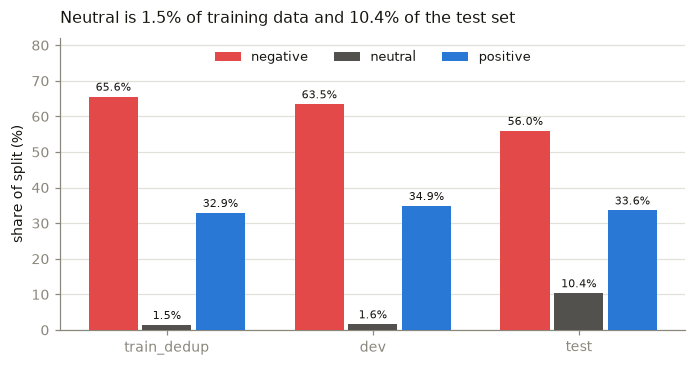

In [3]:
shown = ["train_dedup", "dev", "test"]
shares = pd.DataFrame({
    label: [100 * splits.loc[s, label] / splits.loc[s, "rows"] for s in shown]
    for label in LABELS
}, index=shown)

fig, ax = plt.subplots(figsize=(6.4, 3.4))
width, x = 0.26, np.arange(len(shown))
for i, label in enumerate(LABELS):
    bars = ax.bar(x + (i - 1) * width, shares[label], width * 0.92,
                  label=label, color=COLOUR[label], zorder=3)
    ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=7.5, color=INK)

ax.set_xticks(x, shown)
ax.set_ylabel("share of split (%)")
ax.set_ylim(0, 82)
ax.yaxis.grid(True, color=GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", fontsize=8.5)
ax.set_title("Neutral is 1.5% of training data and 10.4% of the test set",
             loc="left", fontsize=10.5, pad=10)
plt.tight_layout()
plt.show()

The training and test splits are drawn from different label distributions. The
neutral class is close to absent from training and is a tenth of the test set,
which is the single fact that most shapes everything below.

In [4]:
audit = stats["overlap_audit"]
pd.Series({
    "duplicate tweets within train": audit["duplicate_texts_within_train"],
    "train tweets also in test": audit["train_texts_also_in_test"],
    "train tweets also in dev": audit["train_texts_also_in_dev"],
    "dev tweets also in test": audit["dev_texts_also_in_test"],
    "test reachable from train (%)": audit["test_rows_reachable_from_train_pct"],
    "gold agreement on the overlap": audit["label_agreement_on_train_test_overlap"],
    "tweets labelled differently in two splits": audit["contradictory_label_count"],
}, name="count").to_frame()

,count
duplicate tweets within train,512.0000
train tweets also in test,1013.0000
train tweets also in dev,291.0000
dev tweets also in test,266.0000
test reachable from train (%),22.2900
gold agreement on the overlap,0.8776
tweets labelled differently in two splits,124.0000


A fifth of the test set is reachable verbatim from training, and on the shared
tweets the two splits disagree about the correct label 124 times. Those tweets
cannot all be scored correctly by any model, so part of the measured error rate
is the benchmark contradicting itself.

In [5]:
for example in audit["contradictory_examples"][:3]:
    print(f"train: {example['label_in_train']:<9} test: {example['label_in_test']:<9}")
    print(f"       {example['text'][:92]}\n")

train: negative  test: positive 
       today marks one small milestone in the beautiful journey of lifei believe dat im the equival

train: negative  test: positive 
       gaskiya na sha wahala na bils they call me attention seeker e choke

train: negative  test: positive 
       they say out wit old and in wit newbut im not letting go of good friends like uthank u for b



`prepare_data.py` therefore writes three training files rather than one:
`train_full` as released, `train_dedup` with duplicates and overlaps removed,
and `train_full_sub`, a size-matched control used in section 5 to separate the
leakage effect from the extra data volume. Dev and test are never modified.

## 2. Baseline

TF-IDF features into a logistic regression. It needs no pretraining, trains in
seconds, and sets the bar every later model has to clear. This cell trains for
real.

In [6]:
import sys
sys.path.insert(0, str(REPO / "src"))
import baseline

baseline.main(["--features", "word", "--class-weight", "balanced"])

# src/evaluation.py selects matplotlib's headless Agg backend so the scripts can
# write figures without a display. That import has just taken effect here, so
# restore inline rendering for the figures below.
%matplotlib inline

tfidf-word-balanced: trained on 3,486 rows, 11,231 features

tfidf-word-balanced  [dev]
  accuracy     0.6651
  macro F1     0.4240
  weighted F1  0.6575
  negative  P 0.729  R 0.767  F1 0.748  (n=813)
  neutral   P 0.000  R 0.000  F1 0.000  (n=21)
  positive  P 0.539  R 0.510  F1 0.524  (n=447)



Logged to C:\Users\levis\OneDrive\Documents\ALU_Projects\ALU_Summatives\pidgin-finance-sentiment\results\experiments.csv


## 3. Model comparison

Six families, each at a fixed six-epoch budget with the best epoch selected on
dev macro F1. The budget was raised from three after AfroXLM-R was found to peak
at epoch two while XLM-R was still improving: an unequal effective budget made
the gap between them look roughly four times larger than it is.

In [7]:
latest = experiments.sort_values("run_at").drop_duplicates(["experiment", "split"], keep="last")

families = {
    "tfidf-word-balanced": ("TF-IDF + logreg", "none"),
    "bilstm-w2v-unweighted": ("Word2Vec + BiLSTM", "none"),
    "afriberta_base-weighted-afriberta": ("AfriBERTa", "African only, <1GB"),
    "xlm-roberta-base-weighted": ("XLM-R", "100 langs, no pcm"),
    "roberta-base-weighted": ("RoBERTa", "English only"),
    "afro-xlmr-base-weighted": ("AfroXLM-R", "17 African langs, incl pcm"),
}
dev = latest[(latest.split == "dev") & latest.experiment.isin(families)].copy()
dev["model"] = dev.experiment.map(lambda e: families[e][0])
dev["pretraining"] = dev.experiment.map(lambda e: families[e][1])
dev = dev.sort_values("accuracy").set_index("model")
dev[["pretraining", "accuracy", "macro_f1", "weighted_f1", "f1_neutral"]]

,pretraining,accuracy,macro_f1,weighted_f1,f1_neutral
model,,,,,
TF-IDF + logreg,none,0.6651,0.4240,0.6575,0.0
Word2Vec + BiLSTM,none,0.6714,0.4220,0.6587,0.0
AfriBERTa,"African only, <1GB",0.6870,0.4368,0.6766,0.0
XLM-R,"100 langs, no pcm",0.7119,0.4632,0.7069,0.0
RoBERTa,English only,0.7276,0.4674,0.7176,0.0
AfroXLM-R,"17 African langs, incl pcm",0.7432,0.4715,0.7267,0.0


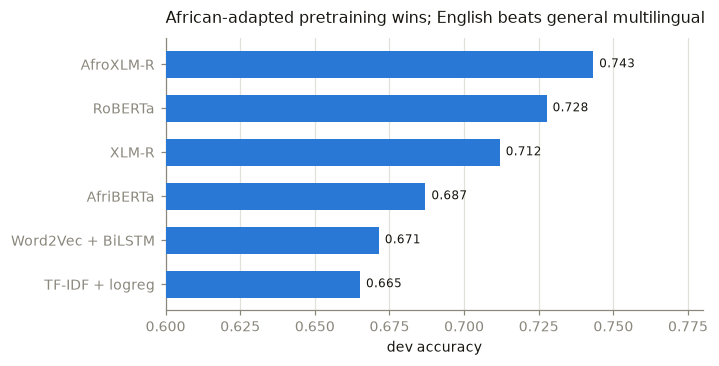

In [8]:
fig, ax = plt.subplots(figsize=(6.6, 3.4))
bars = ax.barh(dev.index, dev.accuracy, color="#2a78d6", height=0.62, zorder=3)
ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=8, color=INK)
ax.set_xlim(0.6, 0.78)
ax.set_xlabel("dev accuracy")
ax.xaxis.grid(True, color=GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
ax.set_title("African-adapted pretraining wins; English beats general multilingual",
             loc="left", fontsize=10.5, pad=10)
plt.tight_layout()
plt.show()

Three observations.

**English-only pretraining beats general multilingual pretraining.** RoBERTa has
never seen an African language, yet it outperforms XLM-R, which covers 100
languages but not Pidgin. Nigerian Pidgin is an English-lexifier creole: most of
its vocabulary is English-derived, so an English subword vocabulary segments it
well, while XLM-R spends capacity on languages that do not help here.

**The ordering reproduces the published one.** Muhammad et al. (2023) report
AfriBERTa 62.3 < XLM-R 63.8 < AfroXLMR 67.6 accuracy for this language. Absolute
values differ because those are test figures and these are dev.

**The sequence model does not beat bag-of-words.** With 3,486 training posts
there is not enough data to use the BiLSTM's extra capacity.

And neutral F1 is 0.000 for every model in the table.

## 4. Final results

The configuration selected on dev, trained on three seeds, with the test split
scored once at the end.

In [9]:
seeds = latest[(latest.split == "test") & latest.experiment.str.contains("seed")]
summary = seeds[["accuracy", "macro_f1", "weighted_f1",
                 "f1_negative", "f1_neutral", "f1_positive"]].agg(["mean", "min", "max"]).T
summary["spread"] = summary["max"] - summary["min"]
summary.round(4)

,mean,min,max,spread
accuracy,0.6968,0.6938,0.7000,0.0062
macro_f1,0.4789,0.4753,0.4831,0.0078
weighted_f1,0.6584,0.6543,0.6629,0.0086
f1_negative,0.7836,0.7814,0.7848,0.0034
f1_neutral,0.0000,0.0000,0.0000,0.0000
f1_positive,0.6529,0.6444,0.6647,0.0203


In [10]:
published = 0.676   # Muhammad et al. (2023), Table 7, AfroXLMR-base on pcm, 5-run mean
ours = summary.loc["accuracy", "mean"]
rows_used, rows_released = 3486, 5122

print(f"published accuracy (5 runs, full release) : {published:.3f}")
print(f"this project     (3 runs, deduplicated)   : {ours:.3f}")
print(f"difference                                : {ours - published:+.3f}")
print(f"training rows used                        : {rows_used} of {rows_released} "
      f"({100 * rows_used / rows_released:.0f}%)")
print(f"seed spread on macro F1                   : {summary.loc['macro_f1', 'spread']:.3f}")

published accuracy (5 runs, full release) : 0.676
this project     (3 runs, deduplicated)   : 0.697
difference                                : +0.021
training rows used                        : 3486 of 5122 (68%)
seed spread on macro F1                   : 0.008


The model exceeds the published figure while training on a third less data,
because the third removed is the leaked third. The seed spread of 0.008 macro F1
sets the noise floor: differences smaller than that are not differences.

Neutral F1 is 0.000 on all three seeds with zero variance. Against 431 neutral
test examples, that is a deterministic failure rather than sampling noise.

## 5. Where the model fails

Error analysis on the test predictions of the seed-42 run.

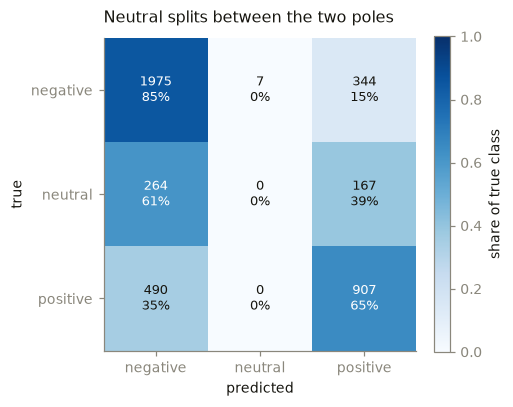

In [11]:
def confusion_frame(key):
    matrix = cache[key]["confusion"]
    return pd.DataFrame(matrix).T.reindex(index=LABELS, columns=LABELS).fillna(0).astype(int)

counts = confusion_frame("afrisenti_test")
shares = counts.div(counts.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(4.5, 3.8))
im = ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{counts.iloc[i, j]}\n{shares.iloc[i, j]:.0%}",
                ha="center", va="center", fontsize=8.5,
                color="white" if shares.iloc[i, j] > 0.5 else INK)
ax.set_title("Neutral splits between the two poles", loc="left", fontsize=10.5, pad=10)
fig.colorbar(im, ax=ax, label="share of true class", fraction=0.046)
plt.tight_layout()
plt.show()

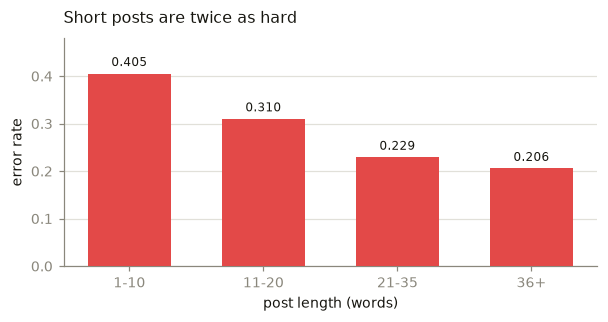

In [12]:
by_length = pd.DataFrame(cache["afrisenti_test"]["error_by_length"]).T
by_length.index.name = "words"

fig, ax = plt.subplots(figsize=(5.6, 3.0))
bars = ax.bar(by_length.index, by_length.error_rate, color="#e34948",
              width=0.62, zorder=3)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8, color=INK)
ax.set_ylabel("error rate")
ax.set_xlabel("post length (words)")
ax.set_ylim(0, 0.48)
ax.yaxis.grid(True, color=GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
ax.set_title("Short posts are twice as hard", loc="left", fontsize=10.5, pad=10)
plt.tight_layout()
plt.show()

Neutral does not fail at random. 61% of neutral posts are called negative and
39% positive: the model has no neutral region, so every post is pushed to a
pole, and it leans negative because 66% of its training data was negative.

Error rate falls steadily with length, from 0.405 on the shortest posts to 0.206
on the longest. Two results cut against the obvious explanation: unseen
vocabulary barely affects the error rate (so Pidgin spelling variation is not
the driver), and posts containing emoji are easier, because emoji carry explicit
sentiment.

## 6. Does it transfer to finance?

The 109 hand-labelled finance posts are longer than AfriSenti's tweets, so the
comparison is made against a **length-matched** subset of the AfriSenti test set.
Without that control, any difference could be explained by post length rather
than by domain.

In [13]:
def row(key, name):
    c = cache[key]
    total = sum(c["true_counts"].values())
    return {
        "set": name, "n": c["n"],
        "neutral %": round(100 * c["true_counts"]["neutral"] / total, 1),
        "accuracy": c["accuracy"],
        "accuracy excl. neutral": c["accuracy_excluding_neutral"],
        "predicted negative %": round(100 * c["pred_counts"]["negative"] / total, 1),
        "actually negative %": round(100 * c["true_counts"]["negative"] / total, 1),
    }

transfer = pd.DataFrame([
    row("afrisenti_lengthmatched", "AfriSenti (length-matched)"),
    row("finance_test", "Finance test"),
]).set_index("set")
transfer

,n,neutral %,accuracy,accuracy excl. neutral,predicted negative %,actually negative %
set,,,,,,
AfriSenti (length-matched),2146,4.3,0.7591,0.7931,66.5,61.7
Finance test,109,46.8,0.3394,0.6379,60.6,16.5


In [14]:
matched, finance = cache["afrisenti_lengthmatched"], cache["finance_test"]
total_drop = matched["accuracy"] - finance["accuracy"]
domain_only = matched["accuracy_excluding_neutral"] - finance["accuracy_excluding_neutral"]
blind_spot = total_drop - domain_only
ceiling = 1 - finance["true_counts"]["neutral"] / finance["n"]

print(f"total accuracy drop                         : {total_drop:.3f}")
print(f"  of which the neutral blind spot meeting")
print(f"  a neutral-heavy domain                    : {blind_spot:.3f}")
print(f"  of which genuine domain difficulty        : {domain_only:.3f}")
print()
print(f"ceiling on the finance set, given the model")
print(f"never predicts neutral                      : {ceiling:.3f}")

total accuracy drop                         : 0.420
  of which the neutral blind spot meeting
  a neutral-heavy domain                    : 0.265
  of which genuine domain difficulty        : 0.155

ceiling on the finance set, given the model
never predicts neutral                      : 0.532


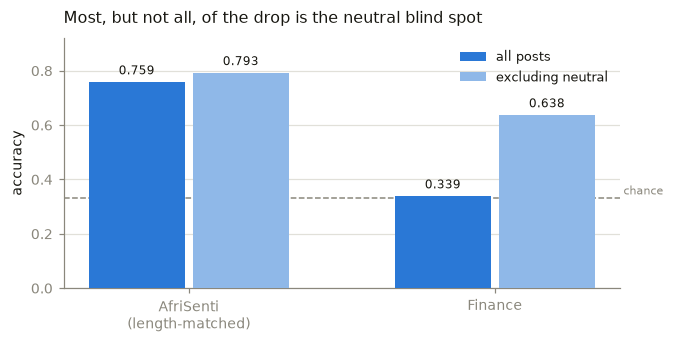

In [15]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
labels = ["AfriSenti\n(length-matched)", "Finance"]
overall = [matched["accuracy"], finance["accuracy"]]
excl = [matched["accuracy_excluding_neutral"], finance["accuracy_excluding_neutral"]]

x, width = np.arange(2), 0.34
b1 = ax.bar(x - width / 2, overall, width * 0.92, label="all posts",
            color="#2a78d6", zorder=3)
b2 = ax.bar(x + width / 2, excl, width * 0.92, label="excluding neutral",
            color="#8fb8e8", zorder=3)
ax.bar_label(b1, fmt="%.3f", padding=3, fontsize=8, color=INK)
ax.bar_label(b2, fmt="%.3f", padding=3, fontsize=8, color=INK)
ax.axhline(1 / 3, color=MUTED, ls="--", lw=1, zorder=2)
ax.text(1.42, 0.345, "chance", fontsize=7.5, color=MUTED)

ax.set_xticks(x, labels)
ax.set_ylabel("accuracy")
ax.set_ylim(0, 0.92)
ax.yaxis.grid(True, color=GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
ax.set_title("Most, but not all, of the drop is the neutral blind spot",
             loc="left", fontsize=10.5, pad=10)
plt.tight_layout()
plt.show()

Two effects are mixed in the headline number and the decomposition separates
them. Neutral is 46.8% of the finance set against 4.3% of the matched AfriSenti
sample, and the model never predicts it, so its ceiling here is 0.532 before it
classifies anything. That accounts for roughly 26 points. The remaining 15.5
points are genuine: with neutral excluded from both sides, accuracy still falls
from 0.793 to 0.638.

The mechanism is visible in the prediction rates in the table above. On
AfriSenti the model predicts negative at close to the true rate, which is what a
reasonable classifier does. On the finance set it keeps predicting negative at
roughly the same rate while the true rate has fallen fourfold. It learned *most
Pidgin tweets are negative* rather than *this is what negative Pidgin looks
like*, and carried that prior into a domain where people are mostly explaining
how wallets and exchanges work.

## 7. Conclusions

A fine-tuned AfroXLM-R reaches 0.697 accuracy on AfriSenti Pidgin, slightly
ahead of the published figure despite training on the deduplicated split. The
model is competitive on the benchmark and close to useless on the domain it
would actually be deployed in.

Three things limit the work.

**The neutral class.** 51 training examples against roughly 3,400. Weighting
that class twenty-two times in the loss did not produce a single neutral
prediction, because weighting moves the decision boundary without supplying
information. NaijaSenti, at around 30,000 Pidgin tweets, is the obvious next
source.

**The finance test set is small and single-annotator.** 109 posts, 18 of them
negative. Per-class figures on 18 examples are indicative, not precise, and no
inter-annotator agreement was obtained.

**Platform is not controlled.** Post length is matched, but these are forum
replies against tweets, so some part of the 15.5-point domain effect is register
rather than subject matter. Separating the two would need Pidgin finance text
from Twitter, which does not currently exist in labelled form.